In [ ]:
import pandas as pd

# فایل CSV را بخوانید
input_file =  "combined_output_final_10H2O2_run2.csv"  # نام فایل ورودی
output_file = "DISPcombined_output_final_10H2O2_run2.csv"   # نام فایل خروجی

# خواندن داده ها
df = pd.read_csv(input_file)

# تابعی برای پردازش ردیفها
def process_rows(row):
    amino1 = row['Amino 1']
    amino3 = row['Amino 3']
    
    # بررسی وجود H2O2 در Amino 1
    if 'H2O2' in amino1:
        # جابجایی مقادیر
        row['Amino 3'] = amino1  # انتقال H2O2 به Amino 3
        row['Amino 1'] = amino3   # انتقال مقدار قبلی Amino 3 به Amino 1
    
    return row

# اعمال تابع به هر ردیف
df = df.apply(process_rows, axis=1)

# ذخیرهسازی دادههای تغییر یافته در فایل جدید
df.to_csv(output_file, index=False)
#print(df)
print(f"Data has been processed and saved to {output_file}.")

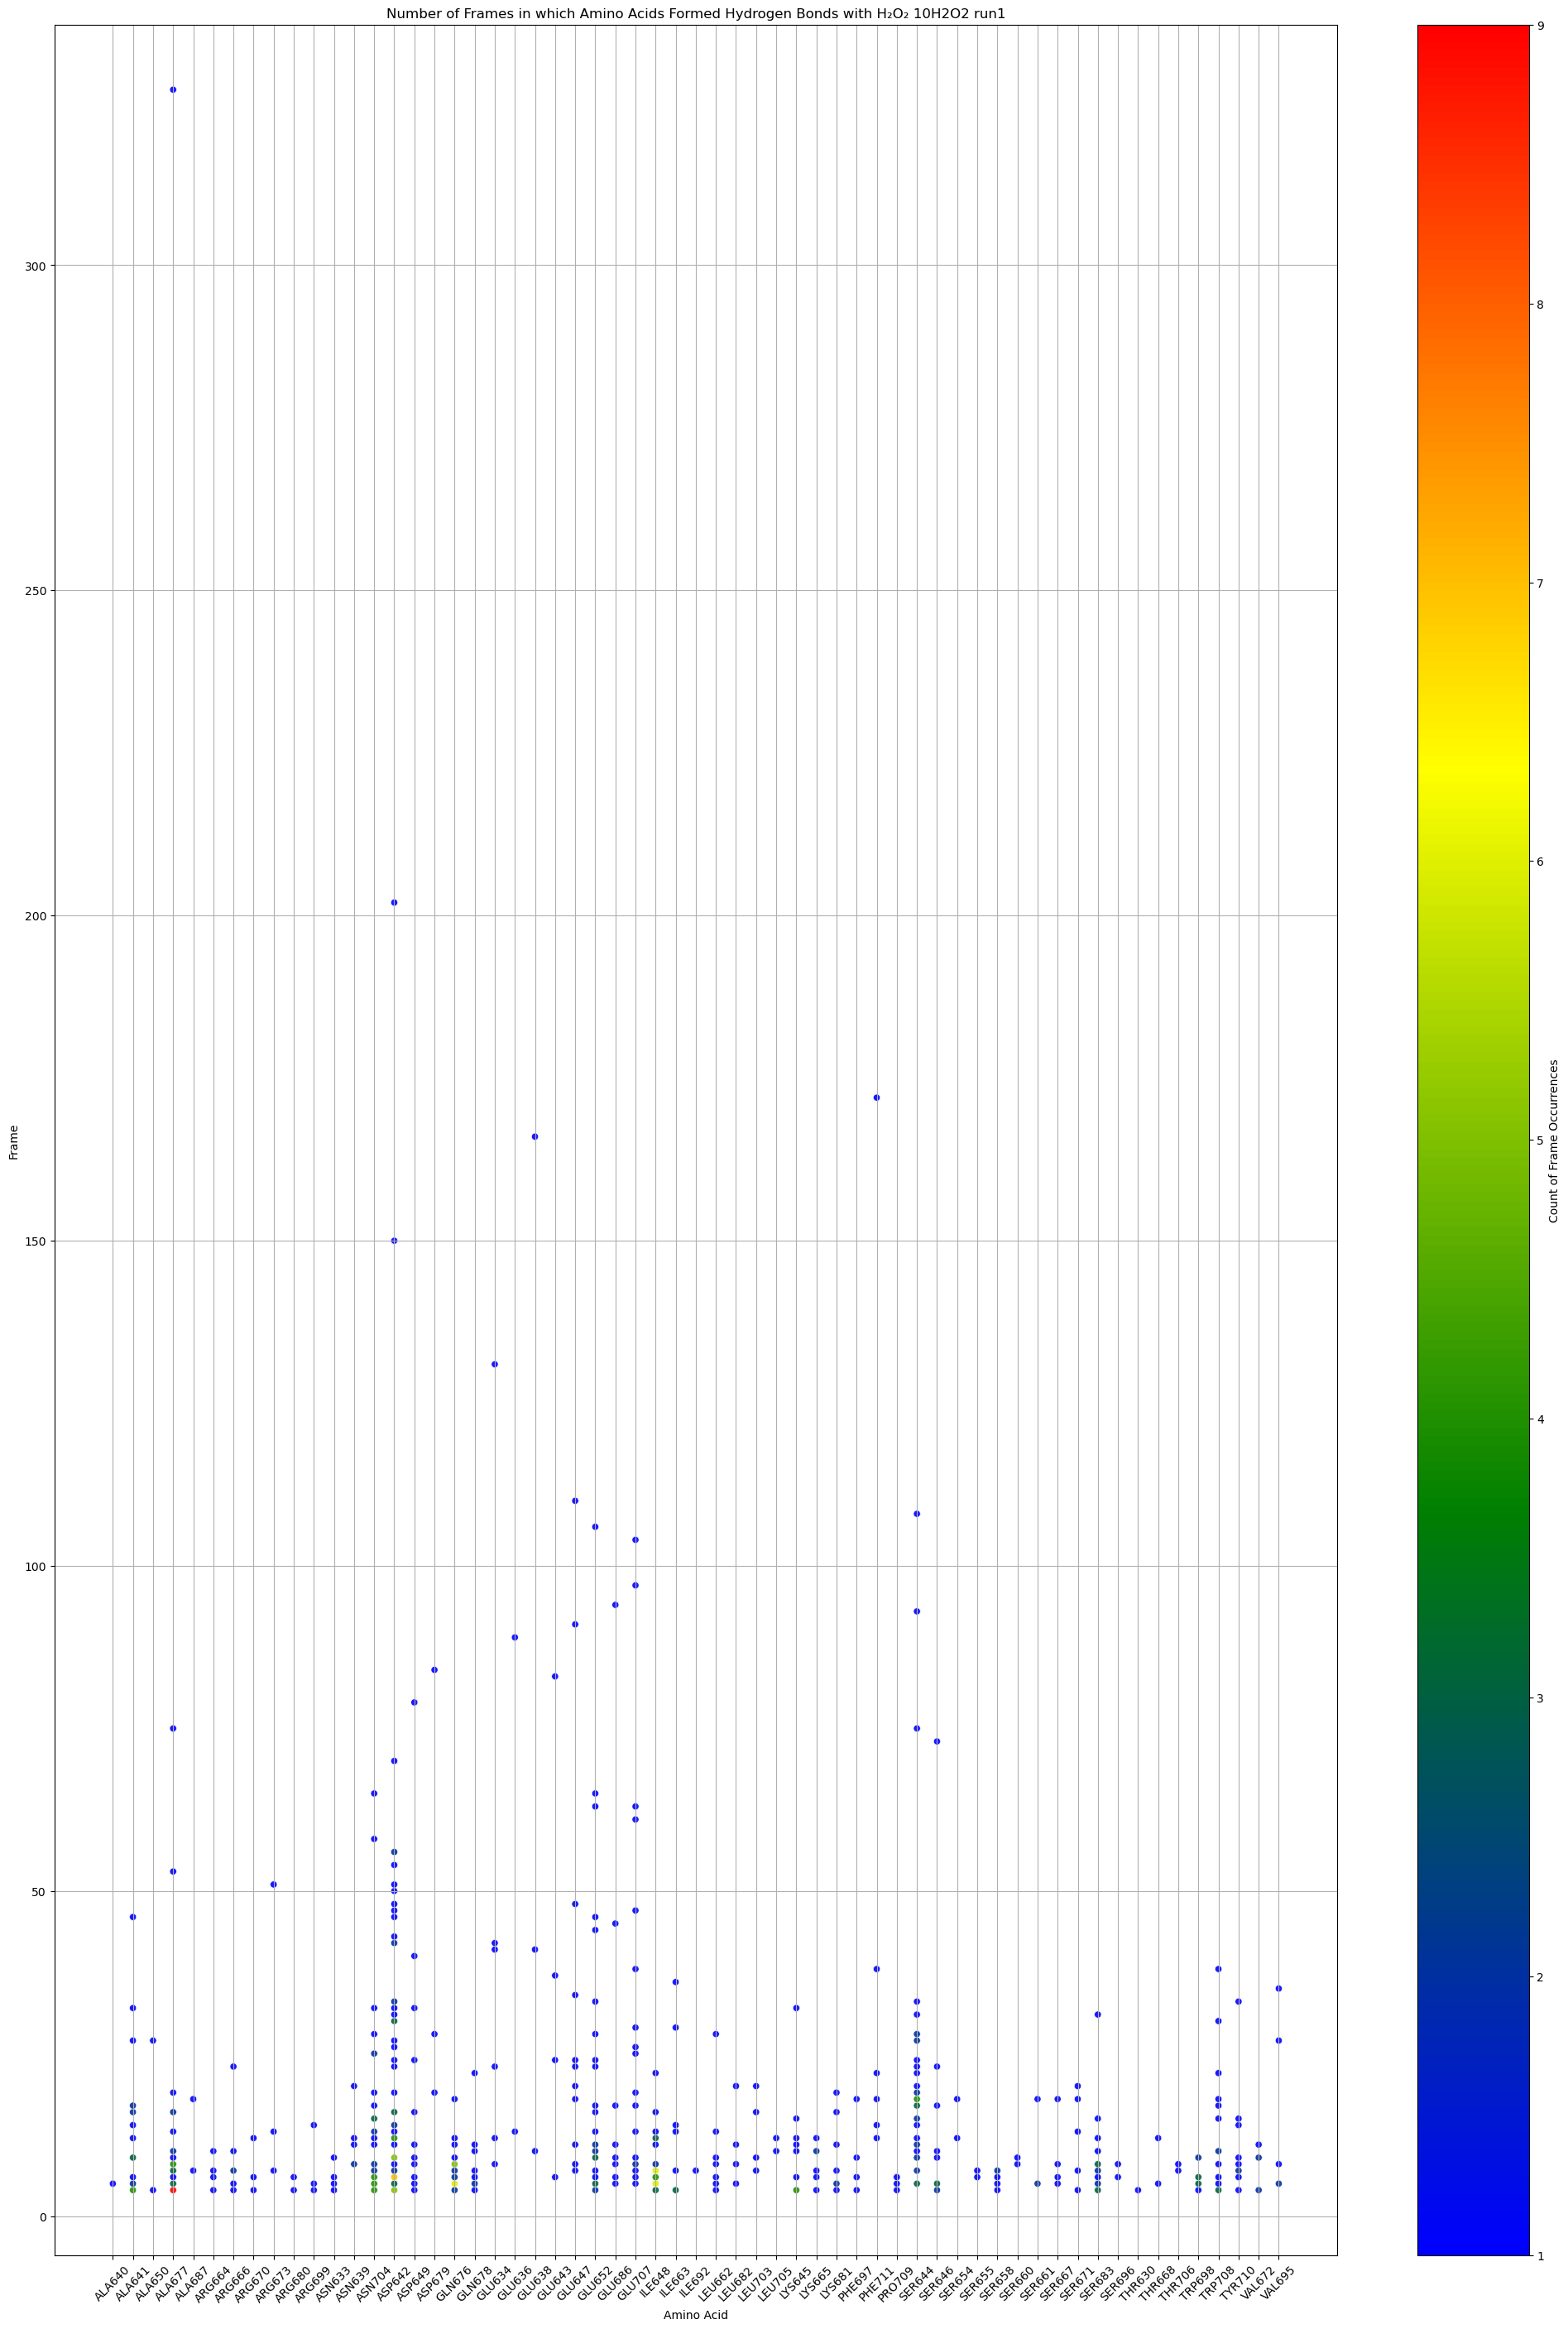

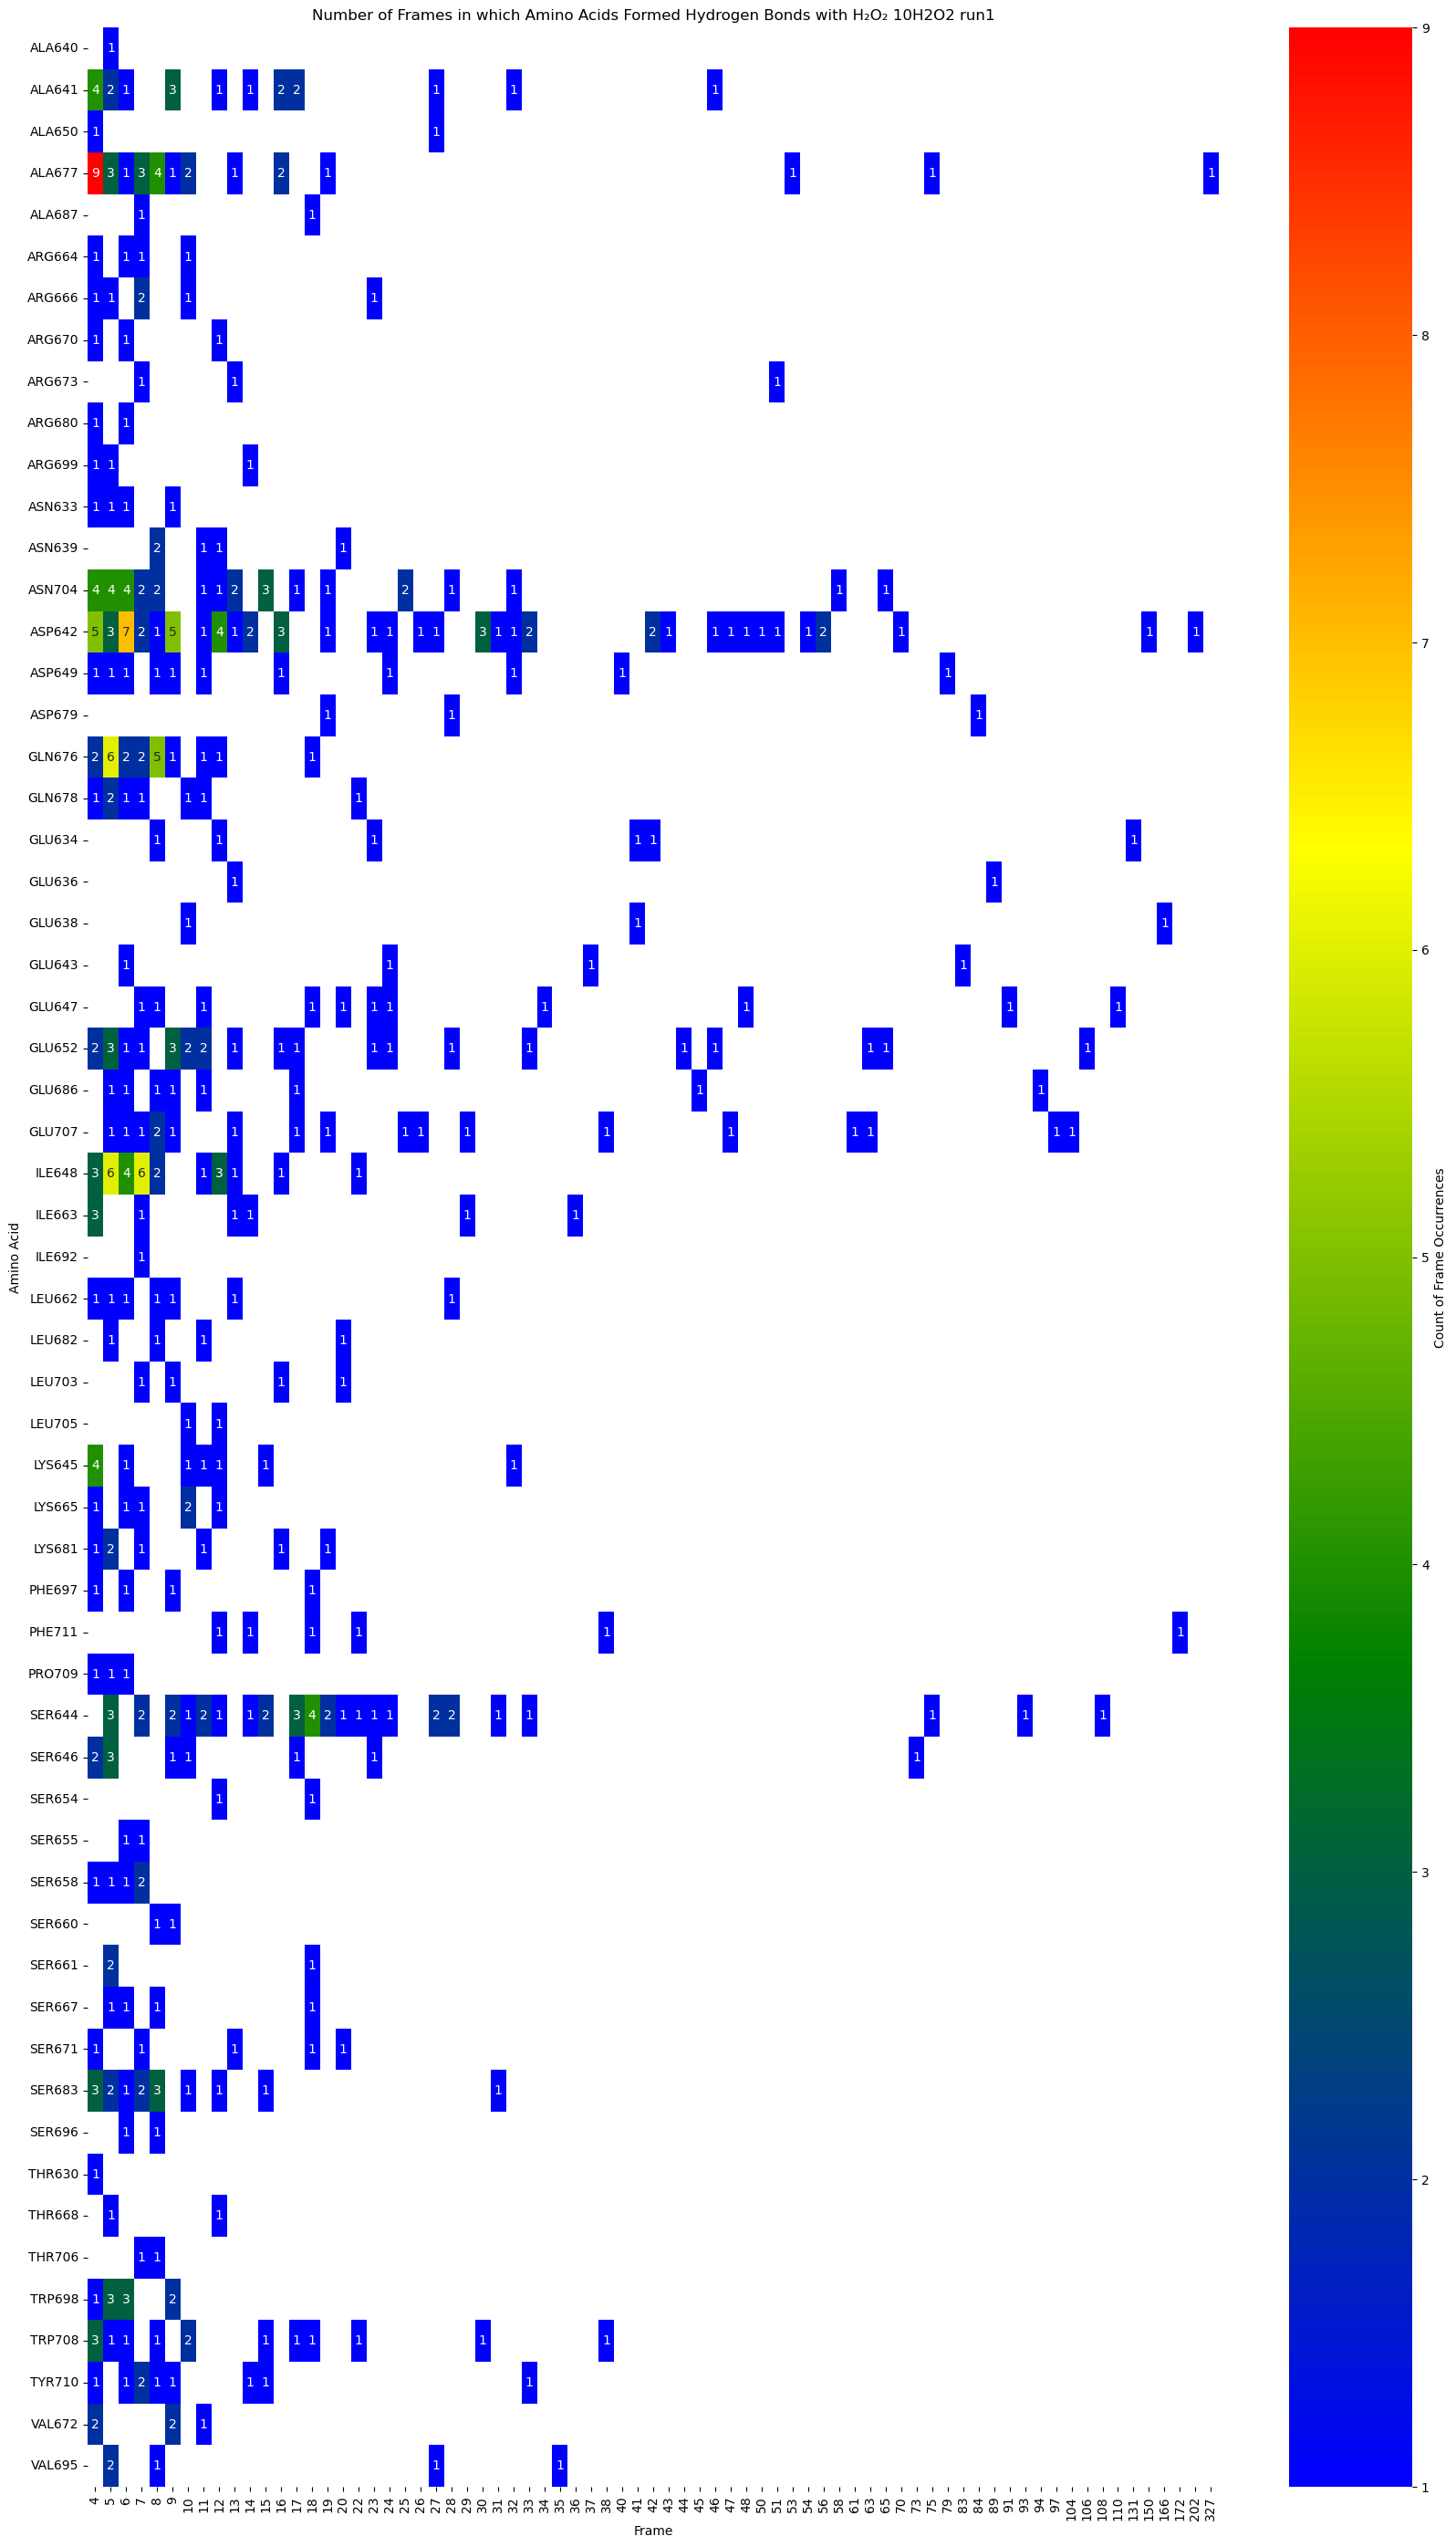

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# بارگذاری دادهها از فایل CSV
file_path = r"C:\Users\Lenovo\Desktop\biophys\10\moratab_10H2O2_run1.csv"  # مسیر فایل CSV خود را وارد کنید
data = pd.read_csv(file_path)

# فرض میکنیم که نام ستون "Amino1" است
# تبدیل فرمت دادههای Amino1 به شکل "GLU629"
data['Amino 1'] = data['Amino 1'].apply(lambda x: f"{x[3:]}{x[:3]}")  # تغییر GLN629 به GLU629

# گروهبندی دادهها بر اساس Amino1 و total_frame_count
grouped_data = data.groupby(['Amino 1', 'total frame count']).size().reset_index(name='count')

colors=["blue","green","yellow","red"]
custom_cmap= LinearSegmentedColormap.from_list("costum_cmap",colors)
# رسم نمودار نقطهای
plt.figure(figsize=(25, 35))
scatter = sns.scatterplot(data=grouped_data, x='Amino 1', y='total frame count', 
                          hue='count', palette=custom_cmap, alpha=0.9, legend=False)

# اضافه کردن راهنمای رنگ
norm = plt.Normalize(grouped_data['count'].min(), grouped_data['count'].max())
sm = plt.cm.ScalarMappable(cmap=custom_cmap, norm=norm)
sm.set_array([])  # برای جلوگیری از هشدارها

# افزودن نوار رنگ به محور فعلی (ax)
cbar = plt.colorbar(sm, ax=scatter.axes)
cbar.set_label('Count of Frame Occurrences')

plt.title('Number of Frames in which Amino Acids Formed Hydrogen Bonds with H₂O₂ 10H2O2 run1')
plt.xlabel('Amino Acid')
plt.ylabel('Frame')
plt.xticks(rotation=45)  # چرخاندن برچسبهای محور افقی برای خوانایی بهتر

# تنظیم محدوده محور عمودی برای جلوگیری از شلوغی
plt.ylim(grouped_data['total frame count'].min() - 10, grouped_data['total frame count'].max() + 10)
plt.grid()
plt.savefig(r"C:\Users\Lenovo\Desktop\biophys\10\scatter_10H2O2_run10.png")
plt.show()

# رسم نمودار جعبهای (Box Plot)
#plt.figure(figsize=(12, 6))
#sns.boxplot(data=grouped_data, x='Amino 1', y='total frame count')
#plt.title('Box Plot of Total Frame Count by Amino Acid')
#plt.xlabel('Amino Acid')
#plt.ylabel('Total Frame Count')
#plt.xticks(rotation=45)
#plt.show()

# رسم نمودار حرارتی (Heatmap)
pivot_table = grouped_data.pivot_table(index='Amino 1', columns='total frame count', values='count', fill_value=None)
#pivot_table=pivot_table.sort_index()

plt.figure(figsize=(20, 35))
heatmap = sns.heatmap(pivot_table, cmap=custom_cmap, annot=True, fmt='.0f',cbar_kws={'label': 'Count of Frame Occurrences'})
plt.title('Number of Frames in which Amino Acids Formed Hydrogen Bonds with H₂O₂ 10H2O2 run1')
plt.xlabel('Frame')
plt.ylabel('Amino Acid')
plt.savefig(r"C:\Users\Lenovo\Desktop\biophys\10\heatmap_10H2O2_run10.png")
#plt.grid()
plt.show()